# YZM 411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme
**Öğrenci:** Sıla Kangal — 230212051

**Çalıştırma sırası:** Hücreleri yukarıdan aşağıya sırayla çalıştırın (*Kernel → Restart & Run All*).

**Giriş dosyaları:** `veri/normal.jpg`, `veri/golge.jpg`, `veri/lamba.jpg` (kendi çekimim, aynı kamera konumu)

**Çıktılar:** `cikti/` klasörü — maskeler, şekiller, `sonuc_tablosu.csv`

**Çekim koşulları:** Telefon: iPhone 13 · AE/AF kilidi açık (pozlama ve odak üç çekimde kilitli). iPhone kamera uygulamasında beyaz dengesi kilitlenemediği için otomatik kaldı; bu nedenle "yalnızca ışık değişti" denemez — renk farkının bir kısmı otomatik beyaz dengesinden gelebilir.
Fotoğraflar sohbet üzerinden aktarıldığı için 1512×2016'ya küçülmüş ve EXIF bilgisi silinmiş hâldedir.

> ⚠️ Her deneyin **TAHMİN** hücresi, deney hücresi çalıştırılmadan önce doldurulmuştur.

In [1]:
# 0) Kütüphaneler ve sürümler
import sys, os, platform
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print("Python    :", platform.python_version())
print("NumPy     :", np.__version__)
print("OpenCV    :", cv2.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pandas    :", pd.__version__)

os.makedirs("cikti", exist_ok=True)
SONUCLAR = []   # (deney, koşul, ölçüt, değer) satırları -> sonuc_tablosu.csv
def kaydet(deney, kosul, olcut, deger):
    SONUCLAR.append({"deney": deney, "kosul": kosul, "olcut": olcut, "deger": deger})

Python    : 3.13.18
NumPy     : 2.5.3
OpenCV    : 5.0.0
Matplotlib: 3.11.2
Pandas    : 3.0.5


## 1) Parametreler
Tüm sabitler burada. **Eşikler normal ışıklı fotoğrafa göre bir kez belirlenip dondurulur; diğer fotoğraflar için değiştirilmez.**

In [2]:
VERI = "veri"
DOSYALAR = {"normal": "normal.jpg", "golge": "golge.jpg", "lamba": "lamba.jpg"}

# Sahne kırpması (x1, y1, x2, y2): masanın üstündeki zemin/halı ve gölge fotoğrafında
# kadraja giren kişi analiz dışı bırakılır. Üç fotoğrafa AYNI kırpma uygulanır.
# Aşağıdaki tüm koordinatlar KIRPILMIŞ görüntüye göredir.
SAHNE_KIRP = (0, 310, 1512, 2016)

# Adım 4: aynı fiziksel bölgeden 3 piksel (x, y)
PIKSELLER = {
    "nesne (hardal tulum)": (820, 970),
    "kagit (beyaz A4)":     (800, 1390),
    "masa (ahsap)":         (200, 1190),
}

# Adım 4 (kontrol): tek piksel tüylü dokuda gürültülü olduğu için bölge ortalamaları da ölçülür (x1, y1, x2, y2)
BOLGELER = {
    "tulum ROI":    (770, 880, 870, 1000),
    "kagit":        (560, 1300, 900, 1550),
    "masa sol":     (80, 1100, 320, 1300),
    "masa sag ust": (1150, 100, 1450, 300),
}

# Adım 5: normal ışıkta nesneden seçilen küçük bölge (x1, y1, x2, y2) — tulumun ortası
NESNE_ROI = (770, 880, 870, 1000)

# Adım 5: DONDURULMUŞ eşikler (alt, üst) — RGB sırası R,G,B ; HSV OpenCV 8-bit: H 0-179, S,V 0-255
# Kural: yalnızca NORMAL fotoğraftaki NESNE_ROI'nin %5 ve %95 yüzdelikleri (bkz. Adım 5 ilk hücre).
# Bir kez belirlendi; gölge ve lamba fotoğrafları için DEĞİŞTİRİLMEDİ.
RGB_ALT, RGB_UST = (106, 72, 2), (221, 196, 112)
HSV_ALT, HSV_UST = (19, 122, 106), (24, 250, 221)

# Adım 6
B_KAYDIRMA = 40
GAMALAR = [0.5, 2.0]

# Adım 7: yazılı/çizgili bölge (x1, y1, x2, y2) ve küçültme oranı
YAZI_ROI = (300, 380, 520, 760)   # etiket: yazı, barkod, QR
OLCEK = 4

## 2) Görüntüleri oku

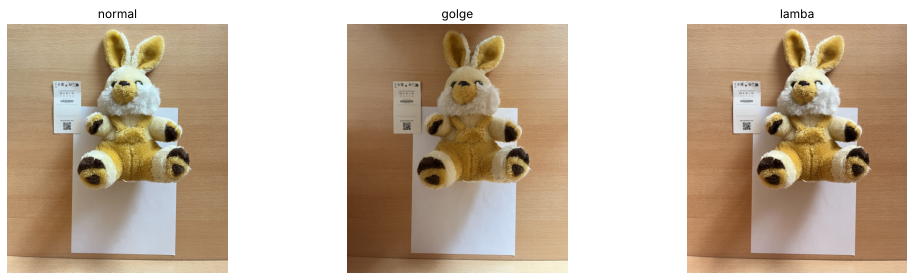

özgün boyutlar: {'normal': (2016, 1512, 3), 'golge': (2016, 1512, 3), 'lamba': (2016, 1512, 3)}
{'normal': (1706, 1512, 3), 'golge': (1706, 1512, 3), 'lamba': (1706, 1512, 3)}


In [3]:
IMG_BGR = {}
for ad, dosya in DOSYALAR.items():
    yol = os.path.join(VERI, dosya)
    im = cv2.imread(yol, cv2.IMREAD_COLOR)
    assert im is not None, f"Okunamadı: {yol}"
    IMG_BGR[ad] = im
print("özgün boyutlar:", {ad: im.shape for ad, im in IMG_BGR.items()})
kx1, ky1, kx2, ky2 = SAHNE_KIRP
IMG_BGR = {ad: im[ky1:ky2, kx1:kx2].copy() for ad, im in IMG_BGR.items()}
IMG = {ad: cv2.cvtColor(im, cv2.COLOR_BGR2RGB) for ad, im in IMG_BGR.items()}   # bundan sonra hep RGB

boyutlar = {ad: im.shape for ad, im in IMG.items()}
print(boyutlar)
assert len(set(boyutlar.values())) == 1, "Üç fotoğraf aynı boyutta olmalı (aynı kamera ayarı)."

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (ad, im) in zip(ax, IMG.items()):
    a.imshow(im); a.set_title(ad); a.axis("off")
plt.tight_layout(); plt.savefig("cikti/01_ozgun_fotograflar.png", dpi=120); plt.show()

**Hizalama kontrolü:** Kamera sabit tutuldu; yine de fotoğraflar arasındaki kaymayı ölçüyoruz (ORB öznitelik eşleme + RANSAC homografi). Kayma birkaç pikselin altındaysa hizalama uygulanmaz, yalnızca raporlanır.

In [4]:
def kayma_olc(kaynak_bgr, hedef_bgr, n=5000):
    g1, g2 = (cv2.cvtColor(i, cv2.COLOR_BGR2GRAY) for i in (kaynak_bgr, hedef_bgr))
    orb = cv2.ORB_create(n)
    k1, d1 = orb.detectAndCompute(g1, None); k2, d2 = orb.detectAndCompute(g2, None)
    m = sorted(cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(d1, d2), key=lambda x: x.distance)[:800]
    p1 = np.float32([k1[x.queryIdx].pt for x in m]); p2 = np.float32([k2[x.trainIdx].pt for x in m])
    H, inl = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0)
    return H, int(inl.sum()), len(m)

for ad in ["golge", "lamba"]:
    H, inl, n = kayma_olc(IMG_BGR[ad], IMG_BGR["normal"])
    print(f"{ad:6s} -> normal: tx={H[0,2]:+.2f} px, ty={H[1,2]:+.2f} px, ölçek={H[0,0]:.4f}, tutarlı eşleşme {inl}/{n}")
    kaydet("hizalama", ad, "tx,ty (px)", f"{H[0,2]:+.2f},{H[1,2]:+.2f}")

golge  -> normal: tx=+0.68 px, ty=-0.76 px, ölçek=0.9998, tutarlı eşleşme 710/800
lamba  -> normal: tx=+0.91 px, ty=+0.66 px, ölçek=0.9982, tutarlı eşleşme 797/800


**Koordinat seçme yardımcısı:** Izgara çizgileri her 100 pikselde bir. Piksel ve ROI koordinatlarını buradan okuyup Parametreler hücresine yazın.

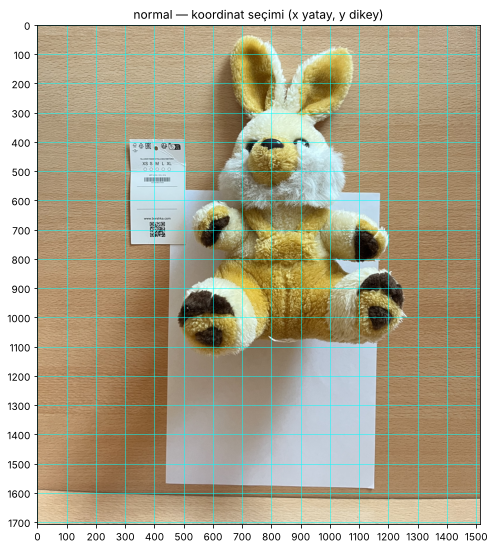

In [5]:
def izgara_goster(im, adim=100, baslik=""):
    plt.figure(figsize=(12, 9)); plt.imshow(im)
    h, w = im.shape[:2]
    plt.xticks(range(0, w, adim)); plt.yticks(range(0, h, adim))
    plt.grid(color="cyan", lw=0.5); plt.title(baslik); plt.show()

izgara_goster(IMG["normal"], baslik="normal — koordinat seçimi (x yatay, y dikey)")

## 3) Adım 4 — Görüntünün sayısal yapısı (Hedef 1)

**TAHMİN (çalıştırmadan önce, 2 cümle):**
> Gölgede ışık azaldığı için kâğıt, tulum ve masanın R, G, B değerlerinin üçü birlikte düşecek. Lambada ise telefonun beyaz dengesi rengi düzelteceği için değerlerin normal ışıktakine yakın kalacağını bekliyorum.

In [6]:
im = IMG_BGR["normal"]
print("shape (H, W, C):", im.shape)
print("dtype          :", im.dtype)
print("değer aralığı  :", int(im.min()), "-", int(im.max()))
kaydet("4", "normal", "shape", str(im.shape)); kaydet("4", "normal", "dtype", str(im.dtype))
kaydet("4", "normal", "min", int(im.min())); kaydet("4", "normal", "max", int(im.max()))

# NumPy erişimi img[y, x, kanal]  ve  BGR -> RGB
x, y = PIKSELLER["nesne (hardal tulum)"]
print(f"\nimg[y={y}, x={x}] BGR (cv2.imread):", IMG_BGR['normal'][y, x])
print(f"img[y={y}, x={x}] RGB (cvtColor)  :", IMG['normal'][y, x])
print(f"img[y={y}, x={x}, 0] BGR'de mavi kanal =", IMG_BGR['normal'][y, x, 0],
      "| RGB'de kırmızı kanal =", IMG['normal'][y, x, 0])
assert np.array_equal(IMG['normal'][..., ::-1], IMG_BGR['normal']), "RGB, BGR'nin kanal tersidir"

shape (H, W, C): (1706, 1512, 3)
dtype          : uint8
değer aralığı  : 0 - 255

img[y=970, x=820] BGR (cv2.imread): [ 10  85 117]
img[y=970, x=820] RGB (cvtColor)  : [117  85  10]
img[y=970, x=820, 0] BGR'de mavi kanal = 10 | RGB'de kırmızı kanal = 117


In [7]:
satirlar = []
for bolge, (x, y) in PIKSELLER.items():
    for kosul, im in IMG.items():
        r, g, b = (int(v) for v in im[y, x])
        satirlar.append({"bölge": bolge, "x": x, "y": y, "koşul": kosul, "R": r, "G": g, "B": b})
        kaydet("4", kosul, f"RGB@{bolge}({x},{y})", f"({r},{g},{b})")
piksel_tablo = pd.DataFrame(satirlar)
piksel_tablo.pivot_table(index=["bölge", "x", "y"], columns="koşul", values=["R", "G", "B"])

B                ...      R              
koşul                          golge  lamba normal  ...  golge  lamba normal
bölge                x   y                          ...                     
kagit (beyaz A4)     800 1390  181.0  151.0  170.0  ...  180.0  176.0  175.0
masa (ahsap)         200 1190   34.0   81.0   88.0  ...  107.0  172.0  166.0
nesne (hardal tulum) 820 970     8.0   16.0   10.0  ...  120.0  123.0  117.0

[3 rows x 9 columns]

**Kontrol:** Tek piksel yerine bölge ortalaması (RGB) ve HSV medyanı:

In [8]:
satir = []
for kosul in IMG:
    hsv = cv2.cvtColor(IMG_BGR[kosul], cv2.COLOR_BGR2HSV)
    for bolge, (x1, y1, x2, y2) in BOLGELER.items():
        r, g, b = IMG[kosul][y1:y2, x1:x2].reshape(-1, 3).mean(0)
        h, s_, v = np.median(hsv[y1:y2, x1:x2].reshape(-1, 3), 0)
        satir.append({"bölge": bolge, "koşul": kosul, "R": round(r, 1), "G": round(g, 1), "B": round(b, 1),
                      "H med": h, "S med": s_, "V med": v})
        kaydet("4-kontrol", kosul, f"ort RGB {bolge}", f"({r:.1f},{g:.1f},{b:.1f})")
        kaydet("4-kontrol", kosul, f"medyan HSV {bolge}", f"({h:.0f},{s_:.0f},{v:.0f})")
bolge_tablo = pd.DataFrame(satir).set_index(["bölge", "koşul"])
bolge_tablo

,,R,G,B,H med,S med,V med
bölge,koşul,,,,,,
tulum ROI,normal,159.5,129.7,50.6,22.0,179.0,157.0
kagit,normal,174.6,169.7,167.9,16.0,21.0,172.0
masa sol,normal,170.3,132.4,94.0,15.0,113.0,171.0
masa sag ust,normal,181.3,161.8,131.6,18.0,69.0,183.0
tulum ROI,golge,130.1,87.9,21.4,18.0,216.0,129.0
kagit,golge,174.0,167.6,165.7,15.0,32.0,171.0
masa sol,golge,107.8,66.6,34.5,13.0,174.0,108.0
masa sag ust,golge,198.4,175.6,145.9,17.0,68.0,200.0
tulum ROI,lamba,160.3,118.7,47.0,19.0,186.5,156.0


**Ne gördüm?** Kırpılmış görüntü 1706 × 1512 × 3, `uint8`, 0–255 (özgün 2016 × 1512). Tek piksellerde gölgede yalnızca masa belirgin karardı (166,127,88 → 107,66,34); kâğıt (175,171,170 → 180,178,181) ve tulum pikseli (117,85,10 → 120,77,8) neredeyse değişmedi. Lambada kâğıdın mavi kanalı 170 → 151'e düştü, yani beyaz kâğıt sıcak/kırmızımsı göründü.

**Neden olabilir?** (1) Gölge sahneye eşit düşmedi: sol taraftaki masa karardı ama kâğıt ışıkta kaldı; sağ üstteki masa ise gölge çekiminde daha parlak (181 → 198 R). (2) Tüylü dokuda tek piksel gürültülü: tulum bölgesinin ortalaması (159,130,51) iken seçilen tek piksel (117,85,10). (3) Otomatik beyaz dengesi lamba ışığının rengini tamamen düzeltmedi.

**Nasıl kontrol ederim?** Bölge ortalamalarına baktım: tulum bölgesi gölgede gerçekten karardı (159,130,51 → 130,88,21) — tek piksel bunu göstermemişti. Tahminim gölge için bölge ortalamasında tuttu, lamba için **tutmadı**.

## 4) Adım 5 — Sabit RGB ve HSV eşikleri (Hedef 2)

Önce normal ışıktaki nesne bölgesinin istatistiklerine bakıp eşikleri **bir kez** seçiyoruz.

In [9]:
x1, y1, x2, y2 = NESNE_ROI
roi_rgb = IMG["normal"][y1:y2, x1:x2].reshape(-1, 3)
roi_hsv = cv2.cvtColor(IMG_BGR["normal"], cv2.COLOR_BGR2HSV)[y1:y2, x1:x2].reshape(-1, 3)
ist = pd.DataFrame(
    np.vstack([np.percentile(roi_rgb, [5, 50, 95], axis=0).T, np.percentile(roi_hsv, [5, 50, 95], axis=0).T]),
    index=["R", "G", "B", "H", "S", "V"], columns=["p5", "medyan", "p95"]).round(1)
ist

,p5,medyan,p95
R,106.0,157.0,221.0
G,72.0,127.0,196.0
B,2.0,47.0,112.0
H,19.0,22.0,24.0
S,122.0,179.0,250.0
V,106.0,157.0,221.0


**Seçilen ve dondurulan eşikler** (Parametreler hücresine yazıldı; normal fotoğraftaki tulum ROI'sinin %5–%95 yüzdelikleri):
RGB → R 106–221, G 72–196, B 2–112 · HSV → H 19–24, S 122–250, V 106–221

**TAHMİN (çalıştırmadan önce, 2 cümle):**
> Gölgede R, G, B birlikte düşeceği için RGB maskesi küçülecek; HSV'de ton (H) değişmediği için HSV maskesi daha az etkilenecek. Lambada telefon beyaz dengesiyle rengi dengeleyeceği için iki maskenin de normal ışıktakine benzer kalacağını tahmin ediyorum.

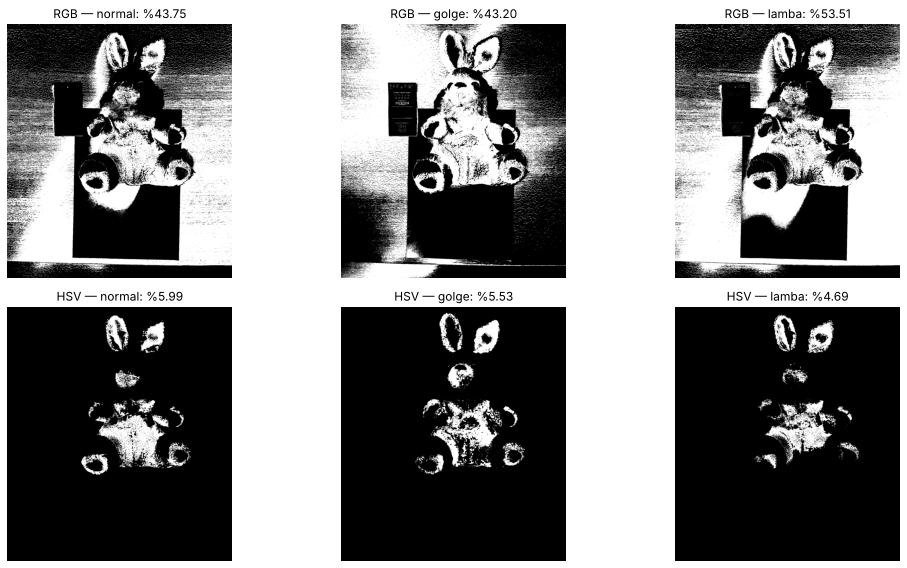

koşul,golge,lamba,normal
uzay,,,
HSV,5.53,4.69,5.99
RGB,43.20,53.51,43.75


In [10]:
def rgb_maske(im_rgb):
    return cv2.inRange(im_rgb, np.array(RGB_ALT, np.uint8), np.array(RGB_UST, np.uint8))

def hsv_maske(im_bgr):
    hsv = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, np.array(HSV_ALT, np.uint8), np.array(HSV_UST, np.uint8))

MASKELER = {}
for kosul in IMG:
    MASKELER[("RGB", kosul)] = rgb_maske(IMG[kosul])
    MASKELER[("HSV", kosul)] = hsv_maske(IMG_BGR[kosul])

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
oran_satir = []
for i, uzay in enumerate(["RGB", "HSV"]):
    for j, kosul in enumerate(IMG):
        m = MASKELER[(uzay, kosul)]
        oran = 100 * np.count_nonzero(m) / m.size
        oran_satir.append({"uzay": uzay, "koşul": kosul, "seçilen piksel": int(np.count_nonzero(m)),
                           "alan oranı %": round(oran, 2)})
        kaydet("5", kosul, f"{uzay} maske alan oranı %", round(oran, 2))
        cv2.imwrite(f"cikti/maske_{uzay}_{kosul}.png", m)
        ax[i, j].imshow(m, cmap="gray"); ax[i, j].set_title(f"{uzay} — {kosul}: %{oran:.2f}"); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("cikti/02_alti_maske.png", dpi=120); plt.show()

oran_tablo = pd.DataFrame(oran_satir).pivot(index="uzay", columns="koşul", values="alan oranı %")
oran_tablo   # NOT: alan oranı doğruluk ölçütü DEĞİLDİR

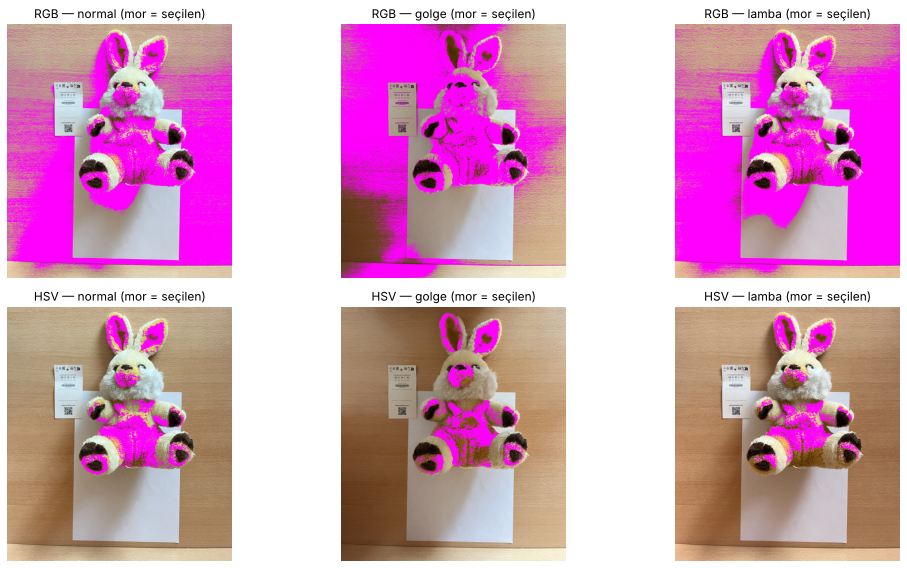

In [11]:
# Maskeyi fotoğrafın üstüne bindir: nesne dışında (ör. masa) seçilen yerleri görmek için
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, uzay in enumerate(["RGB", "HSV"]):
    for j, kosul in enumerate(IMG):
        ust = IMG[kosul].copy(); ust[MASKELER[(uzay, kosul)] > 0] = (255, 0, 255)
        ax[i, j].imshow(ust); ax[i, j].set_title(f"{uzay} — {kosul} (mor = seçilen)"); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("cikti/03_maske_bindirme.png", dpi=120); plt.show()

**Ne gördüm?** Alan oranları — RGB: normal %43,75 · gölge %43,20 · lamba %53,51; HSV: normal %5,99 · gölge %5,53 · lamba %4,69. RGB maskesi normal ışıkta bile masanın büyük bölümünü seçti, lambada daha da büyüdü. HSV maskesi yalnızca ayıcığın hardal kısımlarını seçti; gölgede biraz, lambada daha çok küçüldü. (Alan oranı doğruluk ölçütü değildir: RGB'nin %53'ü "daha iyi" demek değil, daha çok yanlış bölge demektir.)

**Neden olabilir?** RGB eşiği her kanal için ayrı bir aralıktır ve parlaklıkla rengi ayırmaz; masa (≈170,132,94) üç aralığın da içinde kalıyor. HSV'de masanın tonu H≈15 olduğundan 19–24 aralığının dışında. Lambada tulumun ton medyanı 22 → 19'a kaydı (alt sınır) ve bir kısmı aralıktan çıktı → HSV küçüldü; aynı ışık masanın doygunluğunu artırdı (S 113 → 134) → RGB maskesi büyüdü. Gölgede tulumun tonu 22 → 18'e kaydı: HSV de her ışık değişimine dayanıklı değil.

**Nasıl kontrol ederim?** Maske bindirme görseline (mor = seçilen) ve bölge HSV medyanlarına baktım. Gölge tahmini kısmen tuttu (HSV az değişti; RGB çok az küçüldü çünkü maskeye zaten giren masa da kısmen karardı). Lamba tahmini **tutmadı**.

**"Sarı bir arka plan neden hedef gibi seçildi?"** Ahşap masanın rengi hardal tulumla aynı yönde (R > G > B) ve RGB eşiği renkten çok parlaklık aralığı gibi çalışıyor; masa üç kanal aralığına da girdiği için hedef sanıldı. Sıcak lamba ışığı masayı daha doygun/sarı yaptığı için lambada daha fazla masa seçildi. Tonu ayrı kanalda tutan HSV, masayı H farkı sayesinde dışarıda bıraktı.

## 5) Adım 6 — Parlaklık kaydırması ve gama (Hedef 3)

- Parlaklık: $J = \mathrm{clip}(I + b,\ 0,\ 255)$, $b = +40$
- Gama: $J = 255 \cdot (I/255)^{\gamma}$, $\gamma \in \{0.5,\ 2.0\}$ (bu ödevde γ formüldeki üstür)

**TAHMİN — ortalama (çalıştırmadan önce):**
> b=+40 sonrası ortalama 40'tan az artacak, çünkü beyaz kâğıt gibi zaten parlak pikseller 255'te kırpılacak. γ=0.5 görüntüyü aydınlatıp ortalamayı artıracak, γ=2.0 ise karartıp ortalamayı düşürecek.

In [12]:
def parlaklik(I, b):
    J = I.astype(np.float64) + b
    return np.clip(J, 0, 255).astype(np.uint8)

def gama(I, g):
    J = 255.0 * (I.astype(np.float64) / 255.0) ** g
    return np.clip(np.round(J), 0, 255).astype(np.uint8)

# Birim kontrolü (ödevdeki örnek): 64 -> γ=0.5 ≈ 128, γ=2.0 ≈ 16
print("64 -> γ=0.5:", gama(np.array([64], np.uint8), 0.5)[0], "| γ=2.0:", gama(np.array([64], np.uint8), 2.0)[0])

I = IMG["normal"]
donusumler = {"özgün": I, f"b=+{B_KAYDIRMA}": parlaklik(I, B_KAYDIRMA)}
for g in GAMALAR:
    donusumler[f"γ={g}"] = gama(I, g)

ort0 = I.mean()
satir = []
for ad, J in donusumler.items():
    satir.append({"dönüşüm": ad, "ortalama": round(J.mean(), 2),
                  "fark": round(J.mean() - ort0, 2),
                  "255'teki değer %": round(100 * np.mean(J == 255), 2),
                  "0'daki değer %": round(100 * np.mean(J == 0), 2)})
    kaydet("6", ad, "ortalama", round(J.mean(), 2))
    kaydet("6", ad, "255'teki değer %", round(100 * np.mean(J == 255), 2))
donusum_tablo = pd.DataFrame(satir)

# b=+40 için: kırpma olmasaydı beklenen ortalama ve kırpılan değerler
kirpilan = np.mean(I.astype(int) + B_KAYDIRMA > 255) * 100
print(f"Özgün ortalama: {ort0:.2f} | kırpmasız beklenen: {ort0 + B_KAYDIRMA:.2f} | "
      f"ölçülen: {donusumler[f'b=+{B_KAYDIRMA}'].mean():.2f} | 255'te kırpılan kanal değeri: %{kirpilan:.2f}")
kaydet("6", f"b=+{B_KAYDIRMA}", "kırpılan kanal değeri %", round(kirpilan, 2))
donusum_tablo

64 -> γ=0.5: 128 | γ=2.0: 16
Özgün ortalama: 147.56 | kırpmasız beklenen: 187.56 | ölçülen: 186.72 | 255'te kırpılan kanal değeri: %6.86


,dönüşüm,ortalama,fark,255'teki değer %,0'daki değer %
0,özgün,147.56,0.00,0.07,0.11
1,b=+40,186.72,39.15,7.14,0.00
2,γ=0.5,190.80,43.24,0.07,0.11
3,γ=2.0,94.04,-53.52,0.07,0.57


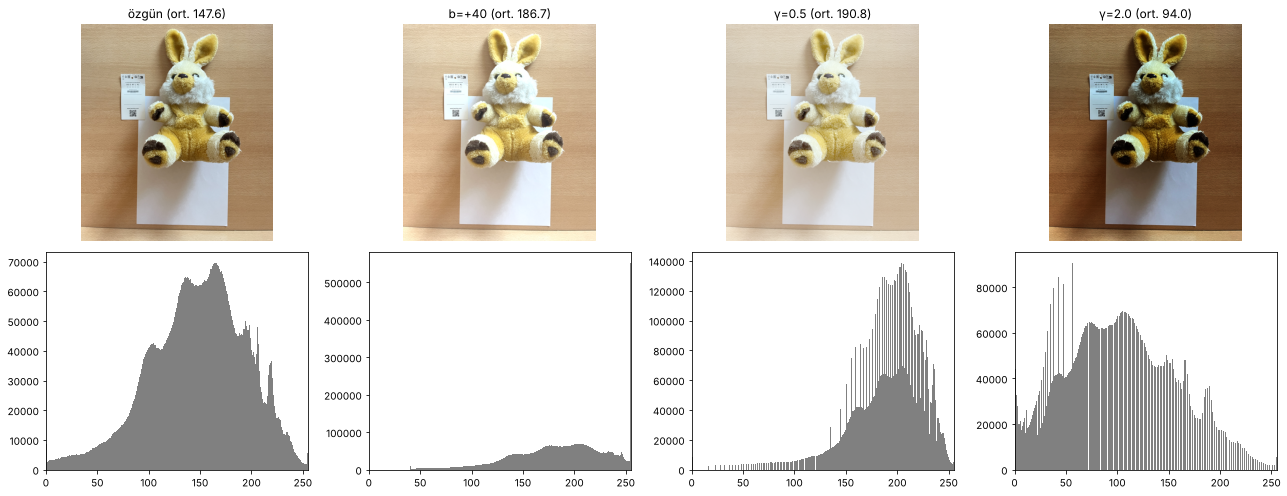

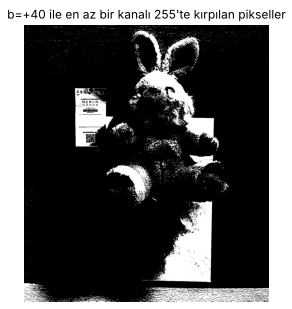

In [13]:
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for j, (ad, J) in enumerate(donusumler.items()):
    ax[0, j].imshow(J); ax[0, j].set_title(f"{ad} (ort. {J.mean():.1f})"); ax[0, j].axis("off")
    ax[1, j].hist(J.ravel(), bins=256, range=(0, 255), color="gray"); ax[1, j].set_xlim(0, 255)
plt.tight_layout(); plt.savefig("cikti/04_parlaklik_gama.png", dpi=120); plt.show()

# Kırpılan pikselleri göster
kirp_maske = ((I.astype(int) + B_KAYDIRMA) > 255).any(axis=2)
plt.figure(figsize=(7, 5)); plt.imshow(kirp_maske, cmap="gray")
plt.title(f"b=+{B_KAYDIRMA} ile en az bir kanalı 255'te kırpılan pikseller"); plt.axis("off")
plt.savefig("cikti/05_kirpilan_pikseller.png", dpi=120); plt.show()

**Ne gördüm?** Özgün ortalama 147,56. b=+40 → 186,72 (artış 39,16; kırpmasız beklenen 187,56). γ=0.5 → 190,80. γ=2.0 → 94,04. Üç tahmin de **tuttu**.

**Neden olabilir?** b=+40'ta kanal değerlerinin %6,86'sı 255'i geçip kırpıldı (beyaz kâğıt ve parlak masa); bu yüzden artış 40'tan az. Kayıp küçük (0,84) çünkü özgünde 255'teki değer yalnızca %0,07. Gama formülünde 0 ve 255 sabit noktalardır, kırpma olmaz; γ < 1 koyu tonları daha çok açar, γ > 1 karartır.

**Nasıl kontrol ederim?** 64 → 128 (γ=0,5) ve 64 → 16 (γ=2,0) birim testi geçti; kırpılan pikselleri ayrı bir maske olarak çizdim (05_kirpilan_pikseller.png) ve beyaz kâğıt üzerinde toplandığını gördüm.

## 6) Adım 7 — Küçültmenin etkisi (Hedef 4)

**TAHMİN (çalıştırmadan önce, 2 cümle):**
> 1/4 küçültmede minik yazı birkaç piksele ineceği için geri büyütünce okunmayacak, çünkü kaybolan ayrıntı geri gelmez. INTER_NEAREST her 4 pikselden yalnızca birini aldığı için barkod çizgilerini atlayıp INTER_AREA'dan daha çok bozacak.

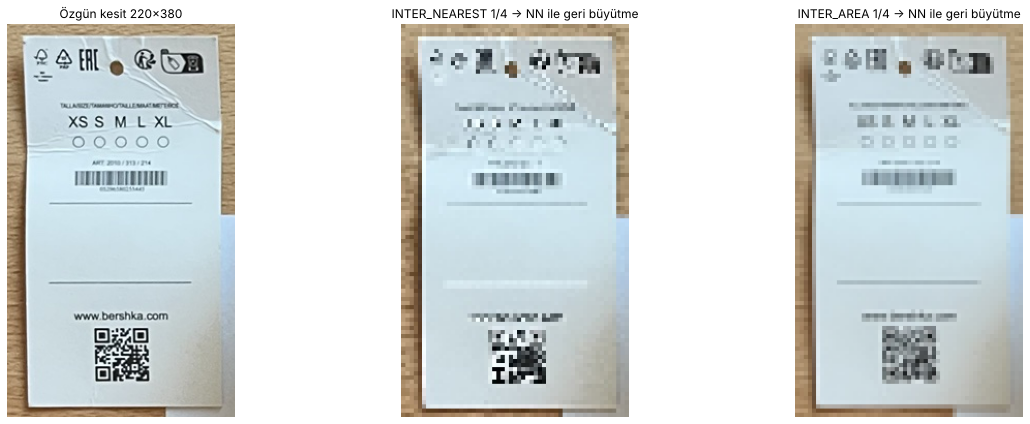

kesit: (380, 220, 3) -> küçük: (95, 55, 3)
INTER_NEAREST  geri büyütülmüş - özgün ortalama mutlak fark: 14.68
INTER_AREA     geri büyütülmüş - özgün ortalama mutlak fark: 11.34


In [14]:
x1, y1, x2, y2 = YAZI_ROI
kesit = IMG["normal"][y1:y2, x1:x2]
h, w = kesit.shape[:2]
kucuk_boyut = (w // OLCEK, h // OLCEK)            # cv2 (genişlik, yükseklik) ister

kucuk = {"INTER_NEAREST": cv2.resize(kesit, kucuk_boyut, interpolation=cv2.INTER_NEAREST),
         "INTER_AREA":    cv2.resize(kesit, kucuk_boyut, interpolation=cv2.INTER_AREA)}
# Yalnızca göstermek için en yakın komşuyla özgün boyuta büyüt
buyuk = {ad: cv2.resize(k, (w, h), interpolation=cv2.INTER_NEAREST) for ad, k in kucuk.items()}

print("kesit:", kesit.shape, "-> küçük:", kucuk["INTER_AREA"].shape)
for ad, B in buyuk.items():
    mae = np.abs(B.astype(int) - kesit[:B.shape[0], :B.shape[1]].astype(int)).mean()
    print(f"{ad:14s} geri büyütülmüş - özgün ortalama mutlak fark: {mae:.2f}")
    kaydet("7", ad, "geri büyütme MAE", round(mae, 2))

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(kesit); ax[0].set_title(f"Özgün kesit {w}×{h}")
for a, (ad, B) in zip(ax[1:], buyuk.items()):
    a.imshow(B); a.set_title(f"{ad} 1/{OLCEK} → NN ile geri büyütme")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("cikti/06_kucultme_karsilastirma.png", dpi=120); plt.show()

**Ne gördüm?** Etiket kesiti 220 × 380 → 55 × 95. INTER_NEAREST'te "XS S M L XL" harfleri kopuk, QR kodda ve barkodda özgünde olmayan iri bloklar (sahte desen) oluştu; geri büyütme hatası (MAE) 14,68. INTER_AREA'da her şey grileşti; "XS S M L XL" bulanık ama seçilebiliyor, "www.bershka.com" ve barkod numarası okunmuyor; MAE 11,34. Tahmin **tuttu**.

**Neden olabilir?** Küçük yazının harf yüksekliği yaklaşık 8–10 piksel; 1/4'te 2–3 piksele iniyor ve harf ayrıntısı örnekleme aralığından küçük kalıyor. NEAREST her 4 × 4 bloktan yalnızca bir pikseli alır: ince çizginin üstüne denk gelirse çizgi kalınlaşır, gelmezse kaybolur (örtüşme/aliasing). AREA 16 pikselin ortalamasını alır, yani önce yumuşatır: sahte desen oluşmaz ama siyah-beyaz kontrast griye döner.

**Nasıl kontrol ederim?** Aynı kesiti yan yana koydum ve geri büyütme hatasını sayısal olarak ölçtüm (NEAREST > AREA). Ek kontrol olarak 1/2 küçültmede aynı karşılaştırmayı yapıp yazının okunur kaldığı ölçeği bulabilirim.

**"Büyütme kaybolan yazıyı neden geri getirmedi?"** Küçültmede her 4 × 4 = 16 piksel tek bir değere indi; 83.600 pikselden 5.225 piksel kaldı. Büyütme yeni bilgi üretmez, yalnızca kalan değerleri kopyalar ya da aralarını doldurur. Harfleri oluşturan ince çizgilerin bilgisi küçültmede silindiği için, hangi enterpolasyon kullanılırsa kullanılsın geri getirilemez.

## 7) Sonuç tablosu

In [15]:
sonuc = pd.DataFrame(SONUCLAR)
sonuc.to_csv("cikti/sonuc_tablosu.csv", index=False, encoding="utf-8-sig")
print(f"{len(sonuc)} satır -> cikti/sonuc_tablosu.csv")
sonuc

56 satır -> cikti/sonuc_tablosu.csv


,deney,kosul,olcut,deger
0,hizalama,golge,"tx,ty (px)","+0.68,-0.76"
1,hizalama,lamba,"tx,ty (px)","+0.91,+0.66"
2,4,normal,shape,"(1706, 1512, 3)"
3,4,normal,dtype,uint8
4,4,normal,min,0
5,4,normal,max,255
6,4,normal,"RGB@nesne (hardal tulum)(820,970)","(117,85,10)"
7,4,golge,"RGB@nesne (hardal tulum)(820,970)","(120,77,8)"
8,4,lamba,"RGB@nesne (hardal tulum)(820,970)","(123,82,16)"
9,4,normal,"RGB@kagit (beyaz A4)(800,1390)","(175,171,170)"


## Tutmayan tahmin
**Lamba (Adım 4–5):** "Telefonun beyaz dengesi rengi düzeltecek, değerler ve maskeler normale yakın kalacak" demiştim. Ölçüm: beyaz kâğıdın B kanalı 168 → 150'ye düştü (H 16 → 9), RGB maskesi %43,75 → %53,51'e büyüdü, HSV maskesi %5,99 → %4,69'a küçüldü. Otomatik beyaz dengesi lambanın sıcak rengini yalnızca kısmen giderdi; bu da "yalnızca ışık değişti" denemeyeceğini gösteriyor.

## Sınırlar
- Pozlama ve odak kilitliydi (AE/AF) ama beyaz dengesi otomatikti.
- Gölge sahneye eşit düşmedi; kâğıt ışıkta kaldı, sağ üstteki masa gölge çekiminde daha parlaktı.
- Fotoğraflar aktarım sırasında 1512 × 2016'ya küçüldü ve JPEG sıkıştırmalı; EXIF bilgisi yok.
- Eşik kuralı (%5–%95) seçilen küçük ROI'ye bağlı; tek sahne ve tek çekimle yapıldı.

## Yapay zekâ beyanı
- **Araç:** Claude (Anthropic)
- **Kullanım amacı:** Notebook kod iskeletinin hazırlanması, tahminlerimi ifade etmeme yardım, ölçümlerin yorumlanması ve rapor düzenlemesi.
- **Etkilediği dosya/hücreler:** Tüm kod hücreleri, tahmin ve yorum metinleri, PDF rapor metni.
- **Nasıl doğruladım:** Sahneyi kendim kurup fotoğrafları kendim çektim; tahmin seçimlerini çalıştırmadan önce kendim yaptım. Kodu kendi verimle Google Colab'da baştan sona çalıştırdım; rapordaki sayıları `sonuc_tablosu.csv` ve çıktı görselleriyle karşılaştırdım.

## Kaynaklar
- YZM 411 ders notları, Hafta 1–2
- OpenCV belgeleri: `cv2.cvtColor`, `cv2.inRange`, `cv2.resize`